<b>DV Experiment 1: Getting Started with Data Visualization</b><br><br><b>Aim:</b> Import retail orders, Dim_Customer.csv, and Iris CSV datasets to examine joined summary tables, category bars, and monthly trend lines.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data_dir = "datasets" if os.path.exists("datasets") else os.path.join("DV_Lab", "datasets")

orders_df = pd.read_csv(os.path.join(data_dir, "superstore_sample.csv"))
customers_df = pd.read_csv(os.path.join(data_dir, "Dim_Customer.csv"))
iris_df = pd.read_csv(os.path.join(data_dir, "iris_sample.csv"))

merged_df = orders_df.merge(customers_df, on="Customer_ID", how="left")
merged_df["Order_Date"] = pd.to_datetime(merged_df["Order_Date"])
merged_df["Year_Month"] = merged_df["Order_Date"].dt.to_period("M").astype(str)

print("Joined Retail Table Preview (Orders + Dim_Customer):")

Joined Retail Table Preview (Orders + Dim_Customer):


In [3]:
print(
    merged_df[["Order_ID", "Order_Date", "Customer_Name", "Loyalty_Tier", "Category", "Sales", "Profit"]]
    .head(7)
    .to_string(index=False)
)

tier_summary = merged_df.groupby("Loyalty_Tier", as_index=False)[["Sales", "Profit", "Quantity"]].sum()
print("\nSales Summary by Customer Loyalty Tier:")
print(tier_summary.round(2).to_string(index=False))

print("\nIris Species Feature Averages:")
print(iris_df.groupby("species").mean(numeric_only=True).round(2))

cat_sales = merged_df.groupby("Category", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)
monthly_sales = merged_df.groupby("Year_Month", as_index=False)["Sales"].sum().sort_values("Year_Month")

 Order_ID Order_Date       Customer_Name Loyalty_Tier        Category   Sales  Profit
ORD-23036 2023-01-02           Diya Nair       Silver Office Supplies 1455.96  199.29
ORD-23199 2023-01-09 Nova Health Systems         Gold Office Supplies  351.12   96.57
ORD-23002 2023-01-12           Diya Nair       Silver      Technology 2008.18  279.93
ORD-23008 2023-01-14      Kabir Malhotra       Silver Office Supplies   90.01   31.81
ORD-23109 2023-01-18  Zenith Retail Corp     Platinum      Technology 2839.10  407.57
ORD-23215 2023-01-22 Nova Health Systems         Gold Office Supplies  378.39   64.81
ORD-23234 2023-01-25     Riya Chatterjee         Gold      Technology 6504.79  484.90

Sales Summary by Customer Loyalty Tier:
Loyalty_Tier     Sales   Profit  Quantity
        Gold 210016.52 27806.69       595
    Platinum 149675.17 20302.79       340
      Silver 194211.51 28387.17       543

Iris Species Feature Averages:
            sepal length (cm)  sepal width (cm)  petal length (cm)  \
s

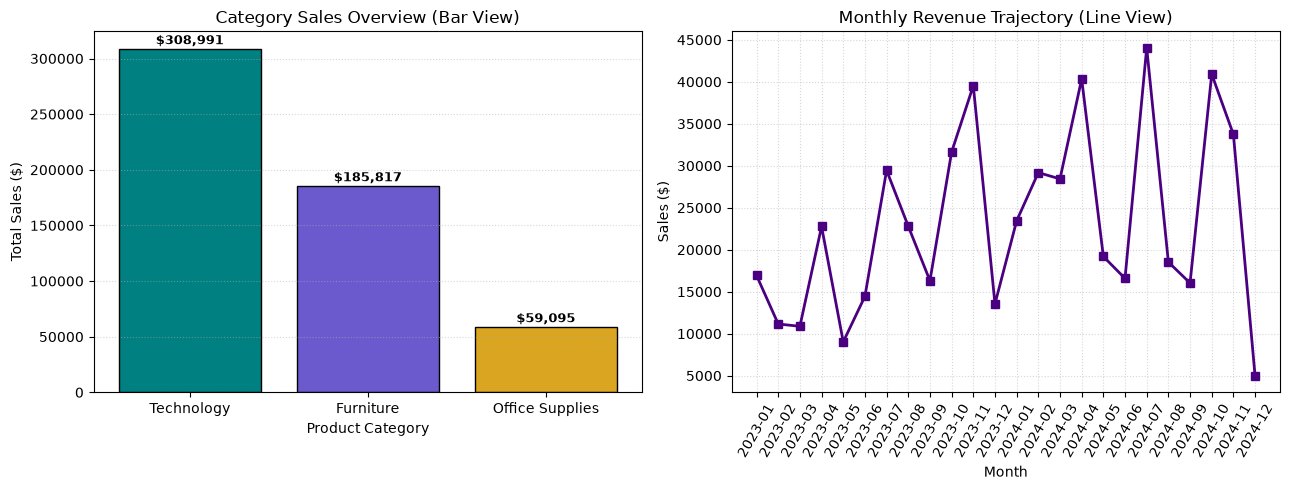

In [4]:
fig, panels = plt.subplots(1, 2, figsize=(13, 5))

panels[0].bar(cat_sales["Category"], cat_sales["Sales"], color=["teal", "slateblue", "goldenrod"], edgecolor="black")
for idx, val in enumerate(cat_sales["Sales"]):
    panels[0].text(idx, val + 1200, f"${val:,.0f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
panels[0].set_title("Category Sales Overview (Bar View)")
panels[0].set_xlabel("Product Category")
panels[0].set_ylabel("Total Sales ($)")
panels[0].grid(True, axis="y", linestyle=":", alpha=0.5)

panels[1].plot(monthly_sales["Year_Month"], monthly_sales["Sales"], marker="s", color="indigo", linewidth=2)
panels[1].set_title("Monthly Revenue Trajectory (Line View)")
panels[1].set_xlabel("Month")
panels[1].set_ylabel("Sales ($)")
panels[1].tick_params(axis="x", rotation=60)
panels[1].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

<b>Observation:</b> Joining Dim_Customer reveals revenue contributions by loyalty tier while bar and line views highlight top categories and year-end peaks.